Urządzenie: cpu


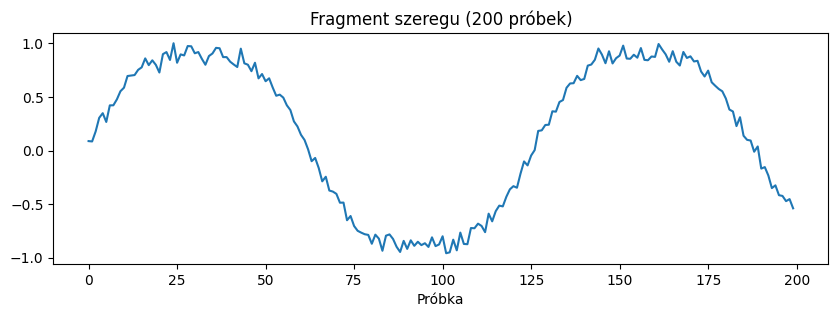

In [ ]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import display

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

def ustaw_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

ustaw_seed(0)

def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1*np.sin(3*t) + 0.05*np.random.randn(n)
    return y.astype(np.float32)

seria = generuj_szereg()
plt.figure(figsize=(10, 3))
plt.plot(seria[:200])
plt.title('Fragment szeregu (200 próbek)')
plt.xlabel('Próbka')
plt.show()

In [ ]:
def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria) - okno):
        X.append(seria[i:i+okno])
        Y.append(seria[i+okno])
    X = np.array(X, dtype=np.float32)[..., None]
    Y = np.array(Y, dtype=np.float32)[:, None]
    return X, Y

def przygotuj_dane(okno):
    X, Y = zrob_okna(seria, okno)
    n_tr = int(0.8 * len(X))
    return (torch.tensor(X[:n_tr], device=DEVICE),
            torch.tensor(Y[:n_tr], device=DEVICE),
            torch.tensor(X[n_tr:], device=DEVICE),
            torch.tensor(Y[n_tr:], device=DEVICE))

class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

Xtr, Ytr, Xte, Yte = przygotuj_dane(30)
print('Trening:', Xtr.shape, 'Test:', Xte.shape)

Trening: torch.Size([1576, 30, 1]) Test: torch.Size([394, 30, 1])


In [ ]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist_test, hist_train = [], []
    n = len(Xtr)

    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        suma_strat = 0.0

        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            suma_strat += loss.item() * len(idx)

        hist_train.append(suma_strat / n)
        model.eval()
        with torch.no_grad():
            hist_test.append(strata(model(Xte), Yte).item())

    return hist_train, hist_test

In [ ]:

ustaw_seed(0)
model_bazowy = ModelRNN(hidden=32, typ='RNN')
hist_train_baza, hist_test_baza = trenuj(
    model_bazowy, Xtr, Ytr, Xte, Yte, epoki=30
)
mse_heurystyki_30 = ((Yte - Xte[:, -1])**2).mean().item()
print(f'RNN bazowy: ostatnia epoka test MSE = {hist_test_baza[-1]:.6f}')
print(f'RNN bazowy: średnia z ostatnich 5 epok = {np.mean(hist_test_baza[-5:]):.6f}')
print(f'Heurystyka (OKNO=30): MSE = {mse_heurystyki_30:.6f}')

plt.figure(figsize=(9, 4))
plt.plot(range(1, 31), hist_train_baza, label='Trening')
plt.plot(range(1, 31), hist_test_baza, label='Test')
plt.xlabel('Epoka'); plt.ylabel('MSE'); plt.title('Model bazowy RNN')
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [ ]:
EPOKI = 20
LR = 1e-2
BATCH = 64
ZIARNA = [0, 1, 2]

wyniki = []
historie = {}
modele_do_wykresu = {}


def eksperyment(nazwa, typ, hidden, okno):
    Xtr, Ytr, Xte, Yte = przygotuj_dane(okno)
    heurystyka = ((Yte - Xte[:, -1])**2).mean().item()
    punktacja = []
    czasy = []
    testy = []
    treningi = []
    liczba_parametrow = None

    for seed in ZIARNA:
        ustaw_seed(seed)
        model = ModelRNN(hidden=hidden, typ=typ).to(DEVICE)
        liczba_parametrow = sum(p.numel() for p in model.parameters())

        if DEVICE == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        hist_train, hist_test = trenuj(model, Xtr, Ytr, Xte, Yte,
                                      epoki=EPOKI, lr=LR, batch=BATCH)
        if DEVICE == 'cuda':
            torch.cuda.synchronize()
        czas = time.perf_counter() - start

        punktacja.append(np.mean(hist_test[-5:]))
        czasy.append(czas)
        testy.append(hist_test)
        treningi.append(hist_train)
        klucz = (nazwa, typ, hidden, okno)
        if klucz not in modele_do_wykresu or punktacja[-1] < modele_do_wykresu[klucz]['wynik']:
            with torch.no_grad():
                model.eval()
                pred = model(Xte[:200]).cpu().numpy().ravel()
            modele_do_wykresu[klucz] = {
                'wynik': punktacja[-1], 'seed': seed, 'pred': pred,
                'prawdziwe': Yte[:200].cpu().numpy().ravel()
            }

    rekord = {'Eksperyment': nazwa, 'Konfiguracja': f'{typ}, hidden={hidden}, OKNO={okno}',
              'Typ': typ, 'hidden': hidden, 'OKNO': okno,
              'Liczba parametrów': liczba_parametrow,
              'MSE średnia': float(np.mean(punktacja)),
              'MSE odch.': float(np.std(punktacja, ddof=1)),
              'Czas treningu [s]': float(np.mean(czasy)),
              'Heurystyka MSE': heurystyka}
    wyniki.append(rekord)
    historie[(nazwa, typ, hidden, okno)] = {
        'test': np.mean(testy, axis=0),
        'train': np.mean(treningi, axis=0),
        'test_runs': testy, 'train_runs': treningi,
    }
    print(f'{nazwa}: {rekord["Konfiguracja"]} -> '
          f'MSE {rekord["MSE średnia"]:.6f} ± {rekord["MSE odch."]:.6f}, '
          f'czas {rekord["Czas treningu [s]"]:.1f} s')
    return rekord

def tabela(nazwa):
    dane = pd.DataFrame([r for r in wyniki if r['Eksperyment'] == nazwa])
    assert len(dane) > 0, 'Najpierw uruchom eksperyment'
    wiersze = [{'Konfiguracja': f'Heurystyka ostatniej próbki, OKNO={o}',
                'Liczba parametrów': 0,
                'Test MSE (średnia ± odchylenie)': f'{h:.6f} (bez losowości)',
                'Czas treningu [s]': 0.0}
               for o, h in sorted(dane.groupby('OKNO')['Heurystyka MSE'].first().items())]
    for _, r in dane.iterrows():
        wiersze.append({'Konfiguracja': r['Konfiguracja'],
                        'Liczba parametrów': int(r['Liczba parametrów']),
                        'Test MSE (średnia ± odchylenie)': f'{r["MSE średnia"]:.6f} ± {r["MSE odch."]:.6f}',
                        'Czas treningu [s]': round(r['Czas treningu [s]'], 2)})
    display(pd.DataFrame(wiersze))

def wykres_testowy(nazwa):
    plt.figure(figsize=(10, 5))
    for r in wyniki:
        if r['Eksperyment'] == nazwa:
            klucz = (nazwa, r['Typ'], r['hidden'], r['OKNO'])
            h = historie[klucz]['test']
            plt.plot(range(1, EPOKI+1), h, label=r['Konfiguracja'])
    plt.title(f'Eksperyment {nazwa} — strata testowa (średnia z 3 uruchomień)')
    plt.xlabel('Epoka'); plt.ylabel('MSE testowe')
    plt.legend(fontsize=8); plt.grid(alpha=0.3)
    plt.show()

A: GRU, hidden=8, OKNO=30 -> MSE 0.003797 ± 0.000055, czas 10.4 s
A: GRU, hidden=16, OKNO=30 -> MSE 0.003737 ± 0.000025, czas 5.4 s
A: GRU, hidden=32, OKNO=30 -> MSE 0.003761 ± 0.000015, czas 6.4 s
A: GRU, hidden=64, OKNO=30 -> MSE 0.003751 ± 0.000100, czas 8.6 s


,Konfiguracja,Liczba parametrów,Test MSE (średnia ± odchylenie),Czas treningu [s]
0,"Heurystyka ostatniej próbki, OKNO=30",0,0.006309 (bez losowości),0.00
1,"GRU, hidden=8, OKNO=30",273,0.003797 ± 0.000055,10.44
2,"GRU, hidden=16, OKNO=30",929,0.003737 ± 0.000025,5.44
3,"GRU, hidden=32, OKNO=30",3393,0.003761 ± 0.000015,6.36
4,"GRU, hidden=64, OKNO=30",12929,0.003751 ± 0.000100,8.63


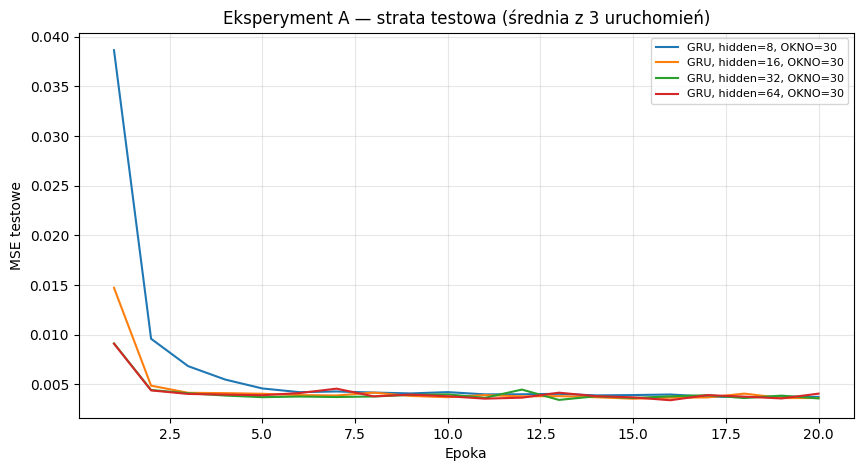

In [ ]:
for h in [8, 16, 32, 64]:
    eksperyment('A', 'GRU', hidden=h, okno=30)

tabela('A')
wykres_testowy('A')

B: GRU, hidden=32, OKNO=10 -> MSE 0.004138 ± 0.000229, czas 2.7 s
B: GRU, hidden=32, OKNO=30 -> MSE 0.003761 ± 0.000015, czas 6.4 s
B: GRU, hidden=32, OKNO=60 -> MSE 0.003425 ± 0.000260, czas 11.9 s
B: GRU, hidden=32, OKNO=120 -> MSE 0.003437 ± 0.000228, czas 23.2 s


,Konfiguracja,Liczba parametrów,Test MSE (średnia ± odchylenie),Czas treningu [s]
0,"Heurystyka ostatniej próbki, OKNO=10",0,0.006281 (bez losowości),0.00
1,"Heurystyka ostatniej próbki, OKNO=30",0,0.006309 (bez losowości),0.00
2,"Heurystyka ostatniej próbki, OKNO=60",0,0.006331 (bez losowości),0.00
3,"Heurystyka ostatniej próbki, OKNO=120",0,0.006313 (bez losowości),0.00
4,"GRU, hidden=32, OKNO=10",3393,0.004138 ± 0.000229,2.74
5,"GRU, hidden=32, OKNO=30",3393,0.003761 ± 0.000015,6.36
6,"GRU, hidden=32, OKNO=60",3393,0.003425 ± 0.000260,11.86
7,"GRU, hidden=32, OKNO=120",3393,0.003437 ± 0.000228,23.20


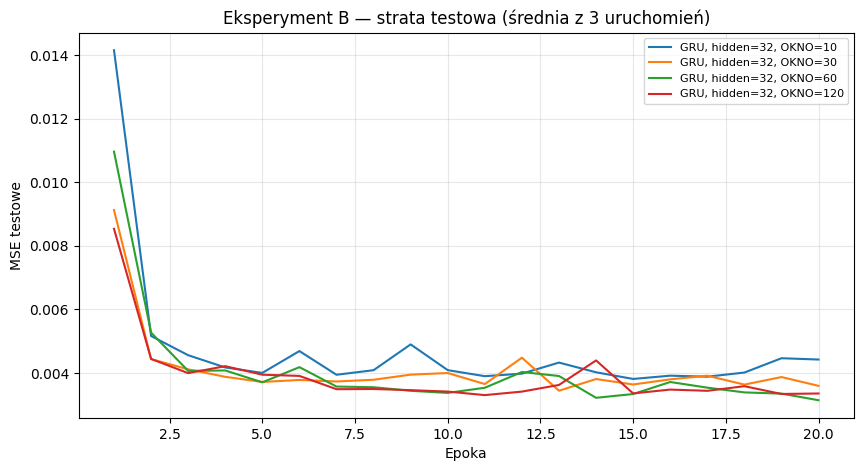

In [ ]:
for okno in [10, 30, 60, 120]:
    eksperyment('B', 'GRU', hidden=32, okno=okno)

tabela('B')
wykres_testowy('B')

C: RNN, hidden=32, OKNO=10 -> MSE 0.004171 ± 0.000302, czas 1.3 s
C: LSTM, hidden=32, OKNO=10 -> MSE 0.004151 ± 0.000137, czas 1.8 s
C: GRU, hidden=32, OKNO=10 -> MSE 0.004138 ± 0.000229, czas 3.0 s
C: RNN, hidden=32, OKNO=120 -> MSE 0.004003 ± 0.000010, czas 9.0 s
C: LSTM, hidden=32, OKNO=120 -> MSE 0.003748 ± 0.000165, czas 11.2 s
C: GRU, hidden=32, OKNO=120 -> MSE 0.003437 ± 0.000228, czas 23.2 s


,Konfiguracja,Liczba parametrów,Test MSE (średnia ± odchylenie),Czas treningu [s]
0,"Heurystyka ostatniej próbki, OKNO=10",0,0.006281 (bez losowości),0.00
1,"Heurystyka ostatniej próbki, OKNO=120",0,0.006313 (bez losowości),0.00
2,"RNN, hidden=32, OKNO=10",1153,0.004171 ± 0.000302,1.29
3,"LSTM, hidden=32, OKNO=10",4513,0.004151 ± 0.000137,1.78
4,"GRU, hidden=32, OKNO=10",3393,0.004138 ± 0.000229,2.96
5,"RNN, hidden=32, OKNO=120",1153,0.004003 ± 0.000010,8.98
6,"LSTM, hidden=32, OKNO=120",4513,0.003748 ± 0.000165,11.16
7,"GRU, hidden=32, OKNO=120",3393,0.003437 ± 0.000228,23.19


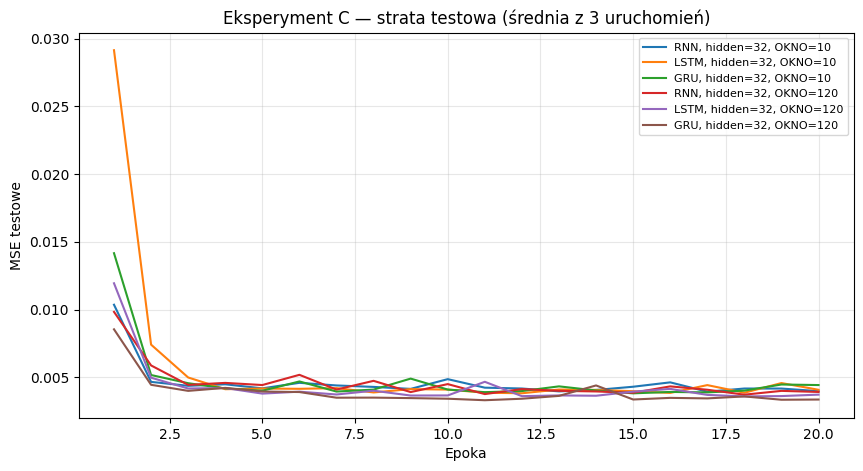

In [ ]:
for okno in [10, 120]:
    for typ in ['RNN', 'LSTM', 'GRU']:
        eksperyment('C', typ, hidden=32, okno=okno)

tabela('C')
wykres_testowy('C')

Najlepsza konfiguracja: GRU, hidden=32, OKNO=60
MSE = 0.003425 ± 0.000260
Powtórzenie do wykresu predykcji: seed=2


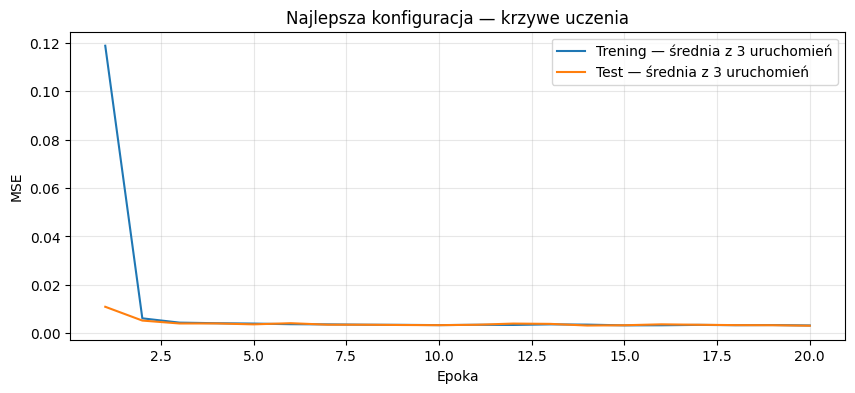

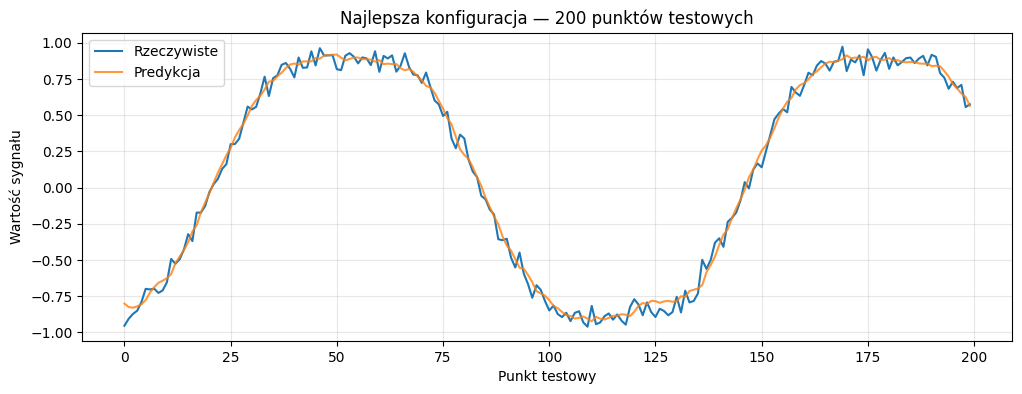

In [ ]:
naj = min(wyniki, key=lambda r: r['MSE średnia'])
klucz = (naj['Eksperyment'], naj['Typ'], naj['hidden'], naj['OKNO'])
h = historie[klucz]
pred_info = modele_do_wykresu[klucz]
print('Najlepsza konfiguracja:', naj['Konfiguracja'])
print(f'MSE = {naj["MSE średnia"]:.6f} ± {naj["MSE odch."]:.6f}')
print(f'Powtórzenie do wykresu predykcji: seed={pred_info["seed"]}')

plt.figure(figsize=(10, 4))
plt.plot(range(1, EPOKI+1), h['train'], label='Trening — średnia z 3 uruchomień')
plt.plot(range(1, EPOKI+1), h['test'], label='Test — średnia z 3 uruchomień')
plt.xlabel('Epoka'); plt.ylabel('MSE')
plt.title('Najlepsza konfiguracja — krzywe uczenia')
plt.legend(); plt.grid(alpha=0.3); plt.show()

plt.figure(figsize=(12, 4))
plt.plot(pred_info['prawdziwe'], label='Rzeczywiste')
plt.plot(pred_info['pred'], label='Predykcja', alpha=0.8)
plt.xlabel('Punkt testowy'); plt.ylabel('Wartość sygnału')
plt.title('Najlepsza konfiguracja — 200 punktów testowych')
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [ ]:
df = pd.DataFrame(wyniki)
display(df[['Eksperyment', 'Konfiguracja', 'Liczba parametrów',
            'MSE średnia', 'MSE odch.', 'Czas treningu [s]', 'Heurystyka MSE']]
        .sort_values(['Eksperyment', 'MSE średnia']))

for nazwa in ['A','B','C']:
    czesc = df[df['Eksperyment']==nazwa]
    zwyciezca = czesc.loc[czesc['MSE średnia'].idxmin()]
    print(f'Najlepszy wynik {nazwa}: {zwyciezca["Konfiguracja"]}, MSE={zwyciezca["MSE średnia"]:.6f}')

print('Sugestia: porównaj średnie MSE z heurystyką dla tego samego OKNA.')
print('Oceń niedouczenie/przeuczenie z wykresu train vs test.')
print('Sprawdź, czy hipotezy A i B pokrywają się z wynikami.')

df.to_csv('wyniki_lab_02.csv', index=False)

,Eksperyment,Konfiguracja,Liczba parametrów,MSE średnia,MSE odch.,Czas treningu [s],Heurystyka MSE
1,A,"GRU, hidden=16, OKNO=30",929,0.003737,0.000025,5.438606,0.006309
3,A,"GRU, hidden=64, OKNO=30",12929,0.003751,0.000100,8.626201,0.006309
2,A,"GRU, hidden=32, OKNO=30",3393,0.003761,0.000015,6.363661,0.006309
0,A,"GRU, hidden=8, OKNO=30",273,0.003797,0.000055,10.438315,0.006309
6,B,"GRU, hidden=32, OKNO=60",3393,0.003425,0.000260,11.857947,0.006331
7,B,"GRU, hidden=32, OKNO=120",3393,0.003437,0.000228,23.201175,0.006313
5,B,"GRU, hidden=32, OKNO=30",3393,0.003761,0.000015,6.361794,0.006309
4,B,"GRU, hidden=32, OKNO=10",3393,0.004138,0.000229,2.740131,0.006281
13,C,"GRU, hidden=32, OKNO=120",3393,0.003437,0.000228,23.189050,0.006313
12,C,"LSTM, hidden=32, OKNO=120",4513,0.003748,0.000165,11.162975,0.006313


Najlepszy wynik A: GRU, hidden=16, OKNO=30, MSE=0.003737
Najlepszy wynik B: GRU, hidden=32, OKNO=60, MSE=0.003425
Najlepszy wynik C: GRU, hidden=32, OKNO=120, MSE=0.003437
Sugestia: porównaj średnie MSE z heurystyką dla tego samego OKNA.
Oceń niedouczenie/przeuczenie z wykresu train vs test.
Sprawdź, czy hipotezy A i B pokrywają się z wynikami.
